In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# load fid
raw_data = pd.read_csv('sample_data/flowmod_C2C005_FID.csv', sep=',', names=['RT', 'FID'])
raw_data.head()

,RT,FID
0,0.000326,2.407383
1,0.000659,2.407063
2,0.000993,2.405869
3,0.001326,2.404210
4,0.001659,2.402816


### Load results data frame

In [ ]:
results_df = pd.read_csv('sample_data/Flow_C2C-005_MSscans.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0


### Molecule m/z
- loop through MS scans and get last four m/z values
- add m/z with highest intensity to data frame

In [12]:
molecul_mz = c2c.getMoleculeMZ(results_df=results_df)

# add to data frame
results_df['Molecule m/z'] = molecul_mz
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049


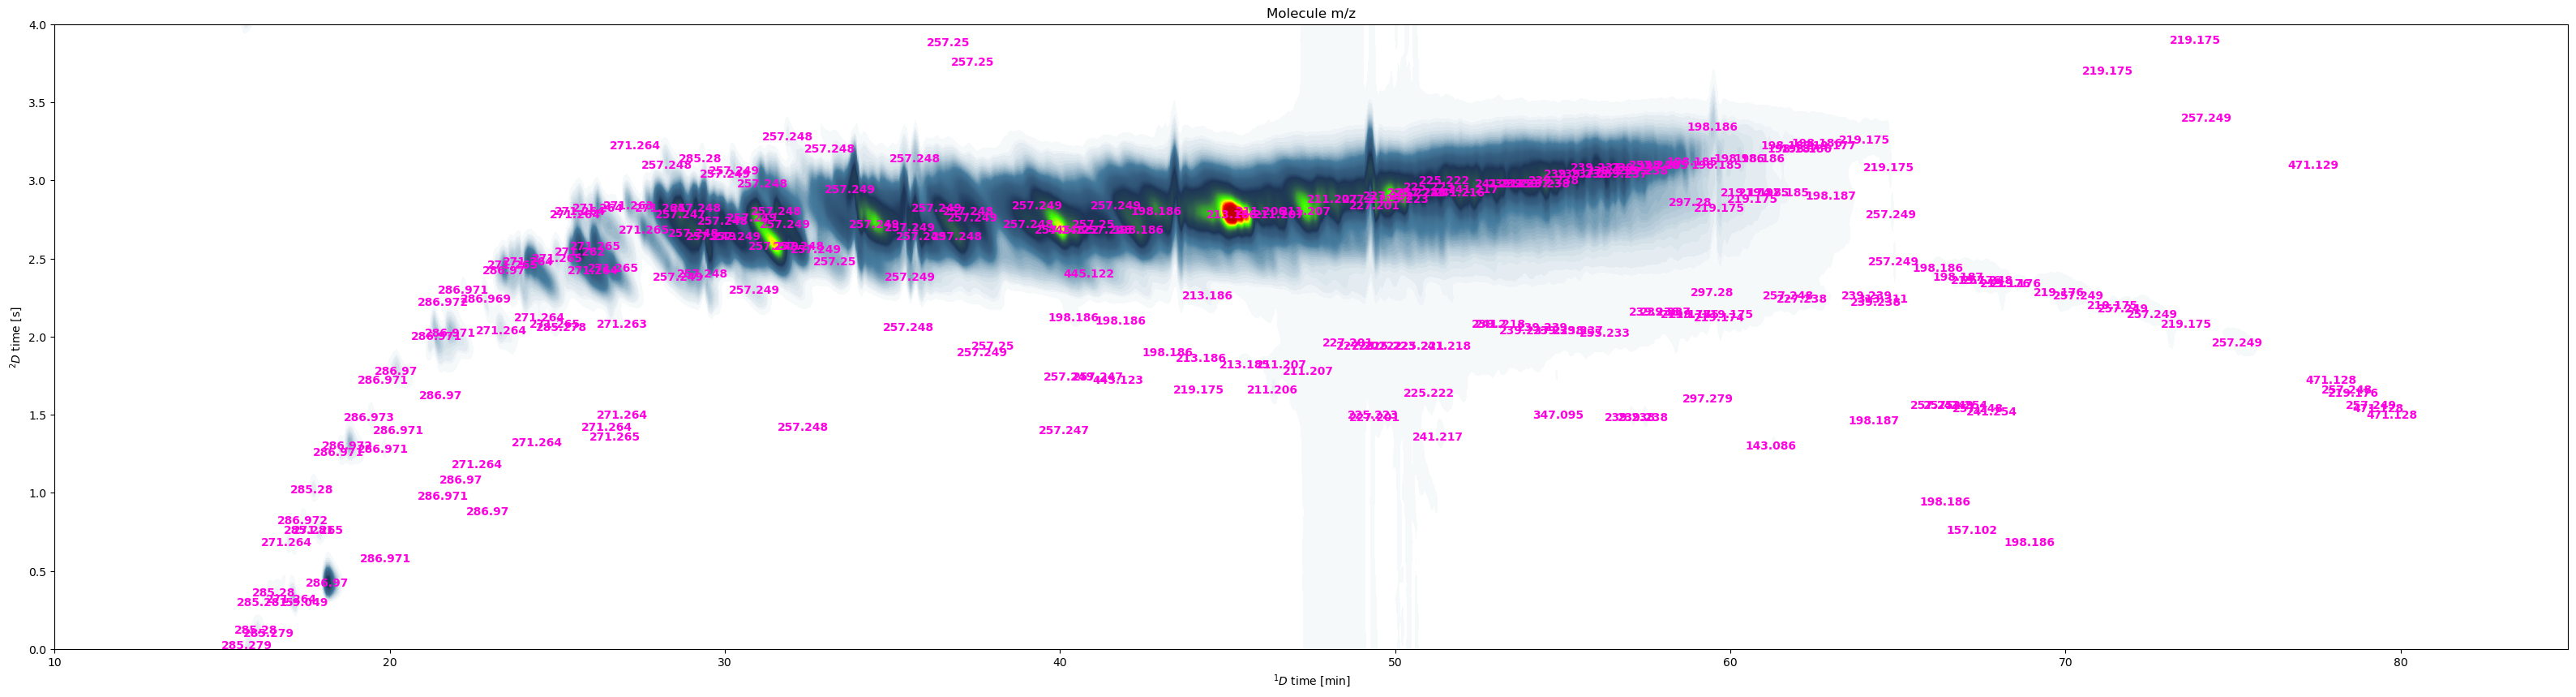

In [13]:
# create scatter plot with molecule m/z
fig, ax = plt.subplots(figsize=(40, 10))

xmin = 10
xmax = 85
ymin = 0
ymax = 4

c2c.plot2d(fig, ax, 
           raw_data['RT'].values, raw_data['FID'].values,
           mod_time= 4, 
           shift = 1.5,
           solvent_cut= 0,
           color_range=(0, 90),
           cbar = False)

for i in range(len(results_df)):
    row = results_df.iloc[i, :]

    if xmin <= row['RT 1d (min)'] <= xmax and ymin <= row['RT 2d (s)'] <= ymax:

        ax.text(row['RT 1d (min)'], row['RT 2d (s)'], 
                s= row['Molecule m/z'],
                va = 'center', ha='center',
                color="#FF00E1", fontdict=dict({'fontweight': 'bold'}))
        
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_title('Molecule m/z')

plt.show()

### Get carbon number from m/z

In [ ]:
hydrocarbon_adducts = dict({5:  [68.5, 73.5],
                    6:  [82.5, 87.5],
                    7:  [96.5, 101.5],
                    8:  [110.5, 115.5],
                    9:  [124.5, 129.5],
                    10: [138.5, 143.5],
                    11: [152.5, 157.5],
                    12: [166.5, 171.5],
                    13: [180.5, 185.5],
                    14: [194.5, 199.5],
                    15: [208.5, 213.5],
                    16: [222.5, 227.5],
                    17: [236.5, 241.5],
                    18: [250.5, 255.5],
                    19: [264.5, 269.5],
                    20: [278.5, 283.5],
                    21: [292.5, 297.5],
                    22: [306.5, 311.5]})

NO_adducts = dict({5: [99.5, 100.5],
                   6: [113.5, 114.5],
                   7: [127.5, 128.5],
                   8: [141.5, 142.5],
                   9: [155.5, 156.5],
                   10: [169.5, 170.5],
                   11: [183.5, 184.5],
                   12: [197.5, 198.5],
                   13: [211.5, 212.5],
                   14: [225.5, 226.5],
                   15: [239.5, 240.5],
                   16: [253.5, 254.5],
                   17: [267.5, 268.5],
                   18: [281.5, 282.5],
                   19: [295.5, 296.5],
                   20: [309.5, 310.5],
                   21: [323.5, 324.5],
                   22: [337.5, 338.5]})

aromates = dict({6: [76.5, 79.5],
                   7: [90.5, 93.5],
                   8: [104.5, 107.5],
                   9: [118.5, 121.5],
                   10: [132.5, 135.5],
                   11: [146.5, 149.5],
                   12: [160.5, 163.5],
                   13: [174.5, 177.5],
                   14: [188.5, 191.5]
                   })

In [15]:
results_df['CNum (m/z) NO'] = c2c.getCNUM_from_MoleculeMZ(results_df['Molecule m/z'], mz_cnum_dict=NO_adducts)
results_df['CNum (m/z) Aromates'] = c2c.getCNUM_from_MoleculeMZ(results_df['Molecule m/z'], mz_cnum_dict=aromates)
results_df['CNum (m/z) Hydrocarbons'] = c2c.getCNUM_from_MoleculeMZ(results_df['Molecule m/z'], mz_cnum_dict=hydrocarbon_adducts)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z) NO,CNum (m/z) Aromates,CNum (m/z) Hydrocarbons
0,15.775659,15.73,0.02,133.171699,1,53.014:5.84 54.009:10.52 55.055:66.5 57.07:37....,285.279,-1,-1,-1
1,16.043993,16.00,0.12,124.874161,1,53.013:10.66 54.009:8.26 55.055:61.12 57.071:3...,285.280,-1,-1,-1
2,16.581326,16.53,0.36,158.873007,1,53.013:8.69 54.009:8.82 55.054:63.09 57.07:37....,285.280,-1,-1,-1
3,17.113993,17.07,0.32,257.106999,1,53.014:35.22 54.009:8.29 55.029:10.3 55.055:26...,271.264,-1,-1,-1
4,17.580326,17.53,0.30,59.976025,1,55.055:7.0 59.049:100.0,59.049,-1,-1,-1


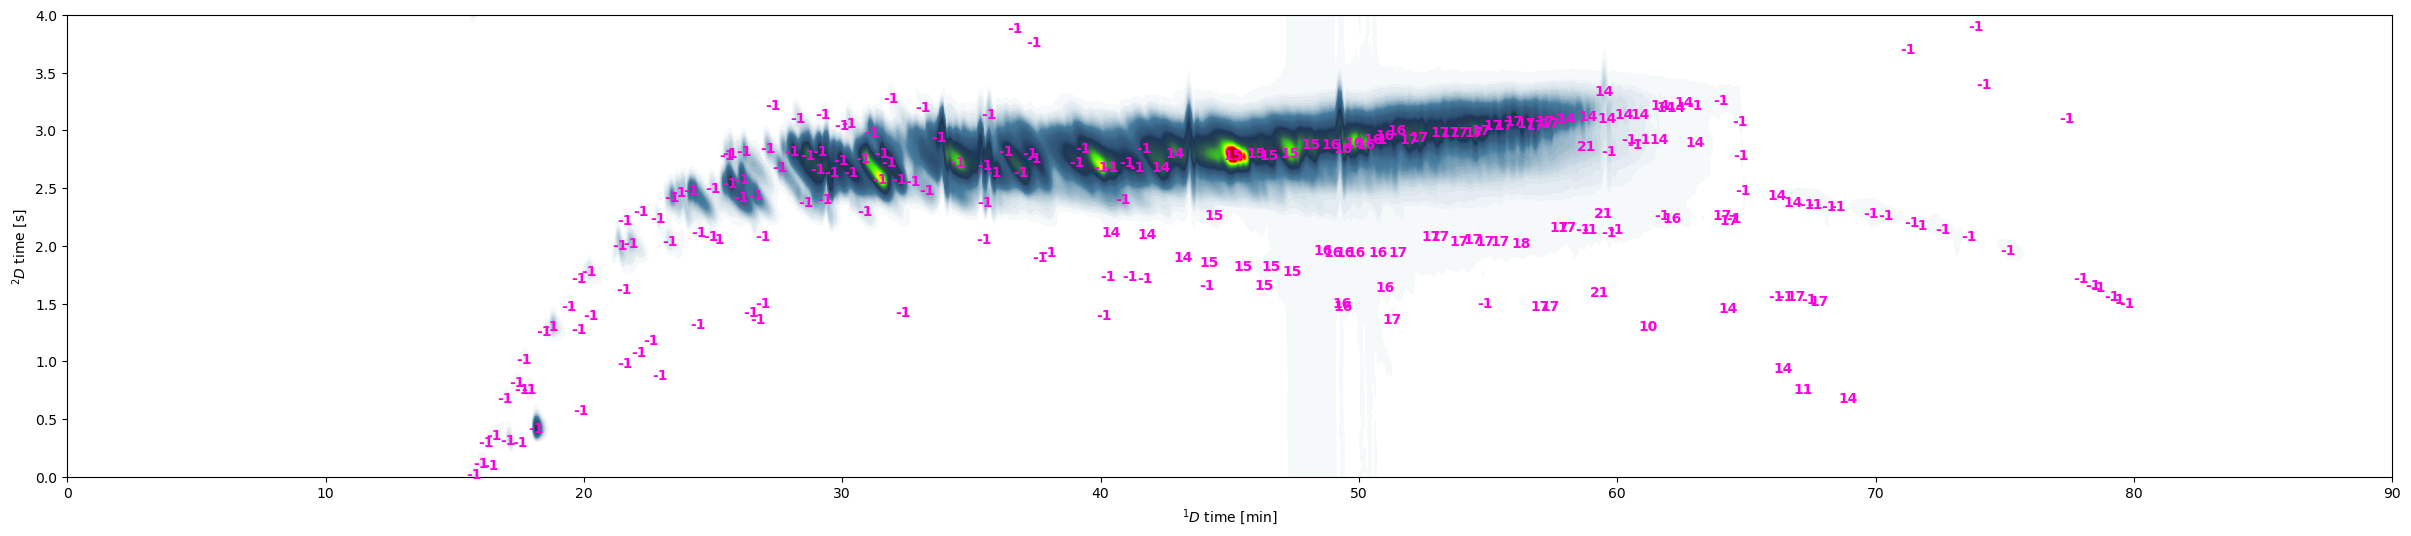

In [16]:
# create scatter plot with molecule m/z
fig, ax = plt.subplots(figsize=(30, 6))

xmin = 0
xmax = 90
ymin = 0
ymax = 4

c2c.plot2d(fig, ax, 
           raw_data['RT'].values, raw_data['FID'].values,
           mod_time= 4, 
           shift = 1.5,
           solvent_cut= 0,
           color_range=(0, 90),
           cbar = False)

for i in range(len(results_df)):
    row = results_df.iloc[i, :]

    if xmin <= row['RT 1d (min)'] <= xmax and ymin <= row['RT 2d (s)'] <= ymax:

        ax.text(row['RT 1d (min)'], row['RT 2d (s)'], 
                # s= row['CNum (m/z) NO'],
                s = row['CNum (m/z) Hydrocarbons'],
                va = 'center', ha='center',
                color="#FF00E1", fontdict=dict({'fontweight': 'bold'}))
        
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.show()

In [ ]:
# export data frame
results_df.to_csv('sample_data/Flow_C2C-005_results.csv', sep=',', index=False)